# Hospital Funnel Plot (readmission rates)

**Family:** Healthcare & life sciences &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Healthcare & life sciences:* Clinical trials, survival, oncology, hospital quality and operations, epidemiology and patient-level records.

> ⚠️ Examples use simulated data. De-identify patient data before analysing it in notebooks: executed notebooks store their outputs.

## Design purpose

Plots each hospital's outcome rate against its volume, with exact binomial control limits around the overall rate that narrow as volume grows. Small hospitals swing furthest by chance, so the limits form a funnel. Only hospitals outside the funnel differ from the benchmark by more than chance explains. This is the standard way to publish comparative hospital performance without a misleading league table.

## When to use

- Compare readmission, mortality or infection rates across hospitals, wards or surgeons of very different size
- Decide which units merit a review (outside 99.8%) and which are within expected variation
- Replace a ranked league table in a public or board report

## Avoid when

- Outcomes are not risk-adjusted and case mix differs a lot (adjust first, then plot observed/expected)
- Volumes are similar everywhere (a dot plot with one interval is simpler)
- Many units fall outside the limits (overdispersion; inflate the limits before drawing conclusions)

## Alternatives

- Caterpillar plot of rates with confidence intervals
- Risk-adjusted CUSUM or VLAD for monitoring one unit over time
- Funnel plot of fund alphas (the same method in the Scientific family)

## Design tips

- What it fixes: a league table puts the smallest, luckiest and unluckiest hospitals at the extremes
- Use exact binomial limits for small volumes; normal approximations are too narrow at low n
- 95% limits are a warning and 99.8% limits an alarm; label only hospitals beyond the outer limits
- Use the national or pooled rate as the target, and state it on the chart

## Example

120 simulated hospitals with 200 to 12,000 discharges a year and a pooled 30-day readmission rate of about 14%. Two large hospitals truly readmit more often (17.5%) and one truly less (11%); the rest differ only by chance.

### Setup

In [1]:
import sys
from pathlib import Path
# This example uses the reusable vizlib package from this repository
# (or `pip install -e .` at the repo root).
sys.path.insert(0, str(Path(".").resolve().parents[1]))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from vizlib.health import funnel_limits

### Data

In [2]:
rng = np.random.default_rng(2005)
k = 120
discharges = np.round(np.exp(rng.normal(7.0, 0.8, k))).astype(int).clip(80, 12000)
true_rate = np.full(k, 0.14)
by_size = np.argsort(-discharges)
true_rate[by_size[[1, 4]]] = 0.175      # two large hospitals truly readmit more
true_rate[by_size[6]] = 0.11            # one truly readmits less
readmitted = rng.binomial(discharges, true_rate)
df = pd.DataFrame({"hospital": [f"H{i:03d}" for i in range(1, k + 1)], "discharges": discharges,
                   "readmitted": readmitted})
df["rate"] = df["readmitted"] / df["discharges"]
target = df["readmitted"].sum() / df["discharges"].sum()
lo998, hi998 = funnel_limits(target, df["discharges"], level=0.998)
df["outside"] = np.where(df["rate"] > hi998, "high", np.where(df["rate"] < lo998, "low", ""))
df[df["outside"] != ""]

,hospital,discharges,readmitted,rate,outside
42,H043,6592,1168,0.177184,high
48,H049,5169,942,0.182240,high
85,H086,3937,430,0.109220,low


### Plot

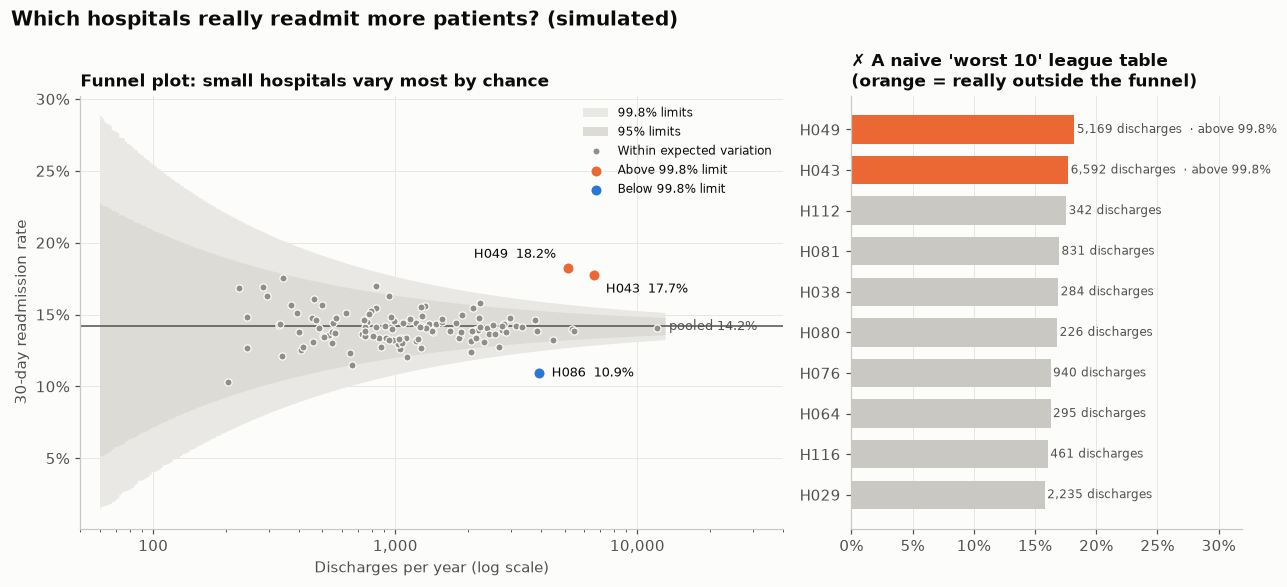

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={"width_ratios": [1.8, 1]})
n_grid = np.unique(np.geomspace(60, 13000, 300).astype(int))
for level, shade, label in ((0.998, "#e9e8e4", "99.8% limits"), (0.95, "#dcdbd6", "95% limits")):
    lo, hi = funnel_limits(target, n_grid, level=level)
    a1.fill_between(n_grid, lo, hi, color=shade, linewidth=0, label=label, step="mid")
a1.axhline(target, color="#52514e", linewidth=1)
a1.text(13000, target, f" pooled {target:.1%}", va="center", fontsize=8.5, color="#52514e")
inside = df["outside"] == ""
a1.scatter(df.loc[inside, "discharges"], df.loc[inside, "rate"], s=22, color="#8f8e88", edgecolor="#fcfcfb",
           linewidth=0.8, zorder=3, label="Within expected variation")
for kind, color, label in (("high", PALETTE[1], "Above 99.8% limit"), ("low", PALETTE[0], "Below 99.8% limit")):
    sel = df["outside"] == kind
    a1.scatter(df.loc[sel, "discharges"], df.loc[sel, "rate"], s=60, color=color, edgecolor="#fcfcfb",
               linewidth=1.2, zorder=4, label=label)
high = df[df["outside"] == "high"].sort_values("rate", ascending=False)
for i, r in enumerate(high.itertuples()):     # alternate above-left / below-right so close pairs don't collide
    up = i % 2 == 0
    a1.annotate(f"{r.hospital}  {r.rate:.1%}", (r.discharges, r.rate), xytext=(-8 if up else 8, 9 if up else -9),
                textcoords="offset points", fontsize=8.5, va="center", ha="right" if up else "left")
for r in df[df["outside"] == "low"].itertuples():
    a1.annotate(f"{r.hospital}  {r.rate:.1%}", (r.discharges, r.rate), xytext=(8, 0),
                textcoords="offset points", fontsize=8.5, va="center")
a1.set_xscale("log")
a1.set_xlim(50, 40000)
a1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
a1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
a1.set_xlabel("Discharges per year (log scale)")
a1.set_ylabel("30-day readmission rate")
a1.set_title("Funnel plot: small hospitals vary most by chance", fontsize=11)
a1.legend(loc="upper right", fontsize=8)

top = df.nlargest(10, "rate").iloc[::-1]
colors = np.where(top["outside"] == "high", PALETTE[1], "#c9c8c3")
a2.barh(top["hospital"], top["rate"], color=colors, height=0.7)
for y, r in enumerate(top.itertuples()):
    a2.text(r.rate + 0.002, y, f"{r.discharges:,} discharges" + ("  · above 99.8%" if r.outside == "high" else ""), va="center", fontsize=8, color="#52514e")
a2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
a2.set_xlim(0, top["rate"].max() * 1.75)
a2.set_title("✗ A naive 'worst 10' league table\n(orange = really outside the funnel)", fontsize=11)
a2.grid(axis="y", visible=False)
fig.suptitle("Which hospitals really readmit more patients? (simulated)", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

## How to read it

The smallest hospitals, on the left, have the most extreme rates but sit inside the funnel: with a few hundred discharges, a rate of 10% or 18% is not unusual. Only three hospitals fall outside the 99.8% limits, exactly the three with a real difference. The league table on the right shows how ranking by raw rate would mostly name small hospitals that are within expected variation.

## Reference

This method comes from the research literature:

- Spiegelhalter, D. J. (2005). Funnel plots for comparing institutional performance. Statistics in Medicine 24(8), 1185–1202. <https://doi.org/10.1002/sim.1970>

---
Standalone script: [`hospital_funnel_plot.py`](hospital_funnel_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)